# Tez İlerleme Sunumu

Kubernetes ortamlarında ağ telemetrisi ve çalışma zamanı olaylarıyla çok katmanlı
anomali tespiti.

**Ana fikir.** Topladığımız veri seti yalnızca küçük değil. Aynı zamanda runtime
katmanı, normal davranış hakkında neredeyse hiçbir şey söylemiyor. Yani sorun "daha
çok veri toplamak" değil; veriyi üretme biçimimizi düzeltmek. Bu düzeltmeyi yapmadan
FAZ 4–7'de elde edeceğimiz sonuçların hiçbiri savunulabilir olmaz.

Sunumun akışı:

| # | Bölüm | Cevabını aradığı soru |
|---|---|---|
| 1 | Tez ne yapıyor | Problem ve özgün katkı nedir? |
| 2 | Nerede duruyoruz | Hangi fazdayız, ne bitti, ne bloke? |
| 3 | Şu ana kadar ne yaptık | Hangi adımı neden attık? |
| 4 | Bulgu | Veri seti neden FAZ 4'e hazır değil? |
| 5 | Plan | FAZ 3.5'te neyi, neden değiştiriyoruz? |
| 6 | Mevcut durum | Kabul kriterleri tutuyor mu? |
| 7 | Sıradaki adım | Ne yapılacak, hangi riskler var? |

**Sayılar canlı.** Bu sunumda elle yazılmış ölçüm yok. Ölçüm gereken her yerde bir kod
hücresi var ve değerler çalıştırma anında `features.parquet` dosyasından hesaplanıyor.
Hesaplama mantığı `src/validate_dataset.py` içinde duruyor; güncel durum ve sayılar
`roadmap/00-durum.md` dosyasında tutuluyor.

Bu sunumun yanında iki teknik notebook var: `data-quality-dashboard.ipynb` (tam
doğrulama) ve `parquet-explorer.ipynb` (ham veriyi inceleme).

## Altyapı — kurulum ve veri tazeliği

Bu hücre anlatının parçası değil; sadece ortamı hazırlıyor. **Sunum §1'de başlıyor.**

Yalnızca sunumdan önce buraya bakmakta fayda var: `features.parquet` ham veriden sonra
üretilmediyse aşağıda bir uyarı çıkıyor. O durumda bütün rakamlar eski koşuya ait olur
ve bunu sunumda belirtmek gerekir.

In [27]:
import sys
from pathlib import Path

# `style.py` bu notebook'un yanında (notebooks/). Kernel cwd'si normalde notebook'un
# dizinidir (JupyterLab ve nbconvert ikisi de böyle); JupyterLab'in kökü repo kökü
# verilmişse diye tek adım aşağısı da denenir.
HERE = Path.cwd().resolve()
if not (HERE / "style.py").is_file():
    HERE = HERE / "notebooks"
sys.path.insert(0, str(HERE))

import style

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from IPython.display import display

import charts

REPO = style.bootstrap()
style.apply_theme()

# Ölçüm mantığının TEK tek kaynağı — burada hiçbir ölçüm yazılmaz:
import validate_dataset as vd
from features.extract_features import ALL_COLS, NET_COLS, RT_COLS

def stamp(path):
    """Dosyanın mtime'ı (UTC)."""
    return pd.Timestamp(path.stat().st_mtime, unit="s", tz="UTC")

FEATURES = REPO / "src/data/features/features.parquet"
RAW_DIR = REPO / "src/data/raw"
WINDOW = "10s"

df = pd.read_parquet(FEATURES)

# Kompakt tazelik bandı — sunumda tek bakışta "bu veri güncel mi" sorusunu cevaplar.
parts = sorted(RAW_DIR.glob("*.part*.parquet"))
newest = max(parts, key=lambda p: p.stat().st_mtime) if parts else None
features_mtime = stamp(FEATURES)
stale = bool(newest) and newest.stat().st_mtime > FEATURES.stat().st_mtime

print(f"features.parquet : {features_mtime:%Y-%m-%d %H:%M} UTC · {len(df)} satır")
print(f"raw part dosyası : {len(parts)} adet" + (
    f" · en yenisi {stamp(newest):%Y-%m-%d %H:%M} UTC" if newest else ""))
print("VERİ ESKİMİŞ — koşu sürüyor ya da `make features` çalıştırılmadı."
      if stale else "features.parquet ham toplamla tutarlı (eskimiş değil)")

summary = vd.summarize(df)
coverage = vd.normal_runtime_coverage(df)

features.parquet : 2026-10-11 13:05 UTC · 101 satır
raw part dosyası : 6 adet · en yenisi 2026-10-15 15:51 UTC
VERİ STALE — koşu sürüyor ya da `make features` çalıştırılmadı.


## 1 · Tez ne yapıyor: problem ve özgün katkı

**Problem.** Kubernetes'te ağ katmanı (Hubble, eBPF akış telemetrisi) ve çalışma
zamanı katmanı (Tetragon, eBPF runtime olayları) ayrı panellerde toplanıyor. İki
katman birbiriyle ilişkilendirilmiyor ve güvenlik riski tek bir birleşik skor olarak
hesaplanmıyor.

**Özgün katkı.** Literatürde bu iki telemetri karar/alert seviyesinde birleştiriliyor.
Tezde ise katmanları feature seviyesinde birleştiriyoruz: ağ ve runtime feature'ları
tek vektörde, tek modelde. FAZ 5 bu iddianın ölçümü olacak. FAZ 4 ise katman başına
baseline; yani "feature seviyesi füzyon, skor seviyesi füzyondan ne kadar iyi?"
sorusunun karşılaştırma tabanı.

**Veriyi neden kendimiz üretiyoruz?** Hubble akışları ile Tetragon olaylarını aynı
kümede ve aynı zaman damgasıyla eşleştiren halka açık bir veri seti yok. Hazır veri
setlerini (CIC-IDS, UNSW-NB15, LID-DS 2021, TON-IoT…) tek katmanlı doğrulama için
kullanıyoruz; füzyonun verisini bu ortamda üretiyoruz. Yani FAZ 0'daki ortam bir
kolaylık değil, veri kaynağının kendisi.

**Hedef mimari.** Aşağıdaki şema bir hedefi gösteriyor, bugünkü durumu değil:

```
Hubble flows ─┐
              ├─→ Telemetry Aggregator ─→ Feature Extraction ─→ Anomaly Scoring ─→ Prometheus ─→ Grafana
Tetragon     ─┘        (Parquet)           (feature vektörü)    ├ network score
 events                                                          ├ runtime score
                                                                 └ FUSION (özgün katkı)
```

| Kutu | Bugünkü durum |
|---|---|
| Telemetry Aggregator (Parquet) | çalışıyor — `src/collector/` |
| Feature Extraction | çekirdek tamam; L7 kapsam dışı |
| Anomaly Scoring | FAZ 4 — kabul kriterleri tutmadığı için bloke |
| FUSION | FAZ 5 — tezin özgün katkısı |
| Prometheus / Grafana | altyapı FAZ 0'da kuruldu; uygulama metrikleri FAZ 6'da |

In [28]:
layers = pd.DataFrame([
    {"katman": "ağ", "kaynak": "Hubble (Cilium)", "feature sayısı": len(NET_COLS),
     "ne görür": "kim kime, hangi porta, hangi L7, verdict",
     "features": ", ".join(NET_COLS)},
    {"katman": "çalışma zamanı", "kaynak": "Tetragon", "feature sayısı": len(RT_COLS),
     "ne görür": "hangi süreç doğdu, hangi binary, hangi dosya",
     "features": ", ".join(RT_COLS)},
])
layers.set_index(["katman", "kaynak", "ne görür"])

,,,n,features
layer,source,ne görür,,
network,Hubble flows (Cilium eBPF),"kim kime, hangi porta, hangi L7, verdict",5,"out_flow_count, out_drop_count, distinct_dest_..."
runtime,Tetragon events (eBPF),"hangi süreç doğdu, hangi binary, hangi dosya",6,"exec_count, exit_count, distinct_binaries, kpr..."


## 2 · Nerede duruyoruz

Faz indeksini ve durumları doğrudan yol haritası dosyasından okuyoruz. Buraya kopyalamıyoruz,
çünkü kopyalanan durum bilgisi zamanla eskiyor. Kritik yol şöyle:

```
FAZ 0 → FAZ 1 (paralel) → FAZ 2 → FAZ 3
   → FAZ 3.5  ← SIRADAKİ, FAZ 4'ün önkoşulu
   → FAZ 4 → FAZ 5 (özgün katkı) → FAZ 6 → FAZ 7 → FAZ 8 → FAZ 8.5 → savunma
```

FAZ 4–7'nin tamamı tek bir veri setine bağlı. Bu yüzden sıradaki iş toplamayı
tekrarlamak değil; veriyi üretme biçimini düzeltmek.

In [30]:
import re


#: Faz indeksindeki durum simgeleri kelimeye çevriliyor. Sunumda simge istemiyoruz
#: ama durum bilgisi kaybolmasın; hücre yalnızca simgeden oluşuyorsa kelime kalıyor.
# Kod noktasıyla yazıldı; kaynakta simge görünmesin.
DURUM_SIMGE = {"\u2705": "tamam", "\U0001F504": "sürüyor", "\u23f3": "bekliyor"}


def roadmap_phases(path):
    """`roadmap/README.md`'deki faz indeksini okur; kopyalamaz.

    Durum bilgisi yol haritası dosyasında yaşıyor (repo kuralı: her olgu tek bir asıl
    dosyada). Deftere kopyalanırsa iki kaynak olur ve biri bayatlar.
    """
    rows = []
    for line in path.read_text(encoding="utf-8").splitlines():
        cells = [c.strip() for c in line.strip().strip("|").split("|")]
        if len(cells) == 4 and cells[0][:1].isdigit():
            # [02](02-faz0-ortam.md) → 02 · ham markdown işaretleri (`**`, `` ` ``) temizlenir
            cells = [re.sub(r"\[([^\]]*)\]\([^)]*\)", r"\1", c) for c in cells]
            cells = [c.replace("**", "").replace("`", "").replace("\u2605", "").strip()   # yol haritası dosyasındaki yıldız işareti
                     for c in cells]
            durum = cells[1]
            for simge, kelime in DURUM_SIMGE.items():
                if simge in durum:
                    durum = durum.replace(simge, "").strip() or kelime
                    break
            rows.append({"phase": cells[0], "status": durum, "output": cells[2]})
    return pd.DataFrame(rows)


INDEX = REPO / "roadmap" / "README.md"
phases = roadmap_phases(INDEX)
if phases.empty:
    print(f"faz indeksi okunamadı — elle bak: {INDEX}")
else:
    print(f"kaynak: {INDEX.relative_to(REPO)}  ({len(phases)} faz)")
phases

kaynak: roadmap/README.md  (10 faz)


,phase,status,output
0,0 — Ortam hazırlığı,tamam (2026-10-11),Çalışan telemetri yığını (iac/setup.sh)
1,1 — Literatür taraması,ilk taslak hazır,bolumler/genelbilgiler.tex + kaynaklar-tez.bib
2,2 — Veri toplama,"pipeline tamam, ölçek yetersiz",src/ hattı + data/raw/*.parquet
3,3 — Ön işleme / özellik,"çekirdek tamam, L7 eksik",features/extract_features.py (11 özellik)
4,4 — Tek katman baseline,bloke (3.5'e bağlı),Katman başına anomali skoru
5,5 — Füzyon,bekliyor,Tezin özgün katkısı — özellik seviyesinde füzyon
6,6 — Dashboard,bekliyor,Prometheus metrikleri + Grafana panelleri
7,7 — Değerlendirme,bekliyor,"Bulgular bölümü verisi, şekil/tablo seti"
8,8 — Tez yazımı,başladı (24 sayfa),KOU FBE formatında tam tez (≥ 70 sayfa)
9,8.5 — Yayın + sunum,bekliyor,Makale + konferans bildirisi + ~100 slayt savunma


## 3 · Şu ana kadar ne yaptık — ve neden

Her faz bir öncekinin bıraktığı eksiği kapatıyor. Aşağıda ne yaptığımızı ve neden
yaptığımızı, elediğimiz alternatiflerle birlikte anlatıyorum.

### FAZ 0 — Ortam: telemetri üreten ölçülebilir bir düzenek

**Neden.** Üzerinde ölçüm yapabileceğimiz bir küme olmadan hiçbir faz başlayamaz. Ama
gerekçe bununla sınırlı değil: tezin verisi hazır bir veri seti değil (bkz. §1).
Füzyonun verisini kendimiz üretmek zorundayız. Yani bu ortam bir altyapı değil, veri
kaynağının kendisi.

**Ne yaptık.** `iac/` altında tek komutla kurulabilen, sürümleri sabitlenmiş ve tekrar
tekrar çalıştırılabilen bir `setup.sh`: Cilium/Hubble Relay ve UI, Tetragon,
kube-prometheus-stack, Online Boutique.

**Kararlar.**
- Hubble Helm chart'ını `agent:false` ile kurduk. Cilium'u zaten OpenStack Magnum
  kuruyor; onu Helm ile yeniden yönetmek çakışmaya yol açardı. Chart yalnızca Relay ve
  UI ekliyor, mTLS için mevcut `cilium-ca`'yı kullanıyor.
- `cl1-kubeconfig.yaml` repoya girmiyor (`.gitignore`); kimlik bilgisi
  commit'lenmemeli.

**Durum.** Tamamlandı. Kalan tek eksik `hubble` CLI; isteğe bağlı ve hiçbir şeyi
bloke etmiyor.

### FAZ 1 — Literatür: boşluğu yazmak

**Neden.** Tezin özgünlük iddiası "literatürün yapmadığını yapmak" üzerine kurulu.
Bu iddianın yazılı olması gerekiyor. Literatür iki telemetriyi karar/alert seviyesinde
birleştiriyor; feature seviyesinde birleştiren bir çalışma yok. Tezin boşluğu tam
olarak bu ayrımda.

**Karar.** Runtime aracı olarak Tetragon'u seçtik. Falco yalnızca referans olarak
kaldı; veri kaynağı değil, karşılaştırma malzemesi.

**Durum.** İlk taslak hazır. Bu faz diğerleriyle paralel yürüyor ve kimseyi bloke
etmiyor; eksikler danışman onayı ve kaynakça tamamlama.

### FAZ 2 — Veri toplama: iki katmanı aynı zaman ekseninde üretmek

**Neden.** Füzyonun ön koşulu, iki katmanın aynı pencerede kaydedilmesi. Farklı
zamanlarda toplanan ağ ve runtime verisi eşleştirilemez; model ne kadar iyi olursa
olsun bu veriyi kullanamaz.

**Ne yaptık.** `src/collector/` altında iki toplayıcı (Hubble gRPC → Parquet, Tetragon
JSON → Parquet), `src/attacks/run_attacks.py` ile etiketli senaryolar ve uçtan uca
koşuyu yapan `collect.sh`.

**Kararlar.**
- İki katmanda ortak anahtar `time` (tz-aware UTC). Bu alanı tesadüfen seçmedik;
  füzyonun tamamı bu anahtar üzerinden kurulacak.
- Toplayıcılar aynı zaman penceresinde paralel çalışıyor (`make -j2`). Aralarında kayma
  olursa eşleşme bozulur.

**Durum.** Hat çalışıyor ve ölçüm üretiyor. Verinin ölçeği ile kalitesi ise bir
sonraki bölümün konusu.

### FAZ 3 — Feature çıkarımı: ham telemetriden model girdisine

**Neden.** Model ham akışı ve ham olayı doğrudan kullanamaz. `(namespace, pod)` ve
window düzeyinde sayısal bir vektöre ihtiyaç var.

**Ne yaptık.** 11 feature (5 network + 6 runtime) tek bir tek şemada
(`src/features/extract_features.py`), window bazlı örnekleme ve `make features` ile
`features.parquet` üretimi.

**Kararlar.**
- Etiket hizalamasını zaman tabanlı yaptık.
- **L7'yi denedik ve kapsam dışı bıraktık.** `proxy-visibility` annotation'ı endpoint'i
  policy-enforcement moduna sokuyor ve pod'un DNS'ini kırıyor. Doğru çözüm açık bir
  `CiliumNetworkPolicy` yazmak; ama o değişiklik bütün demo endpoint'lerini enforcement
  moduna sokar ve uzun toplama koşusundan önce doğrulanmamış bir datapath değişikliği
  veri setini sessizce bozabilirdi. Ayrıca L7 akışı doğrulanmadan flatten kodu yazmak
  boşa emek olurdu.
  **Bedeli:** `dns-exfil` senaryosu hâlâ yalnızca `exec_count` ile ayrışıyor. Yani
  `nslookup` süreç doğurduğu için görünüyor; DNS sızıntısının gerçek sinyali değil.
  Bunu tezde bir tespit boşluğu olarak yazacağız.
- Normalizasyon ve encoding işlerini FAZ 4'e bıraktık; tek katman baseline orada
  kurulacak.
- `out_drop_count` bu ortamda hep 0 geliyor; ölü feature, ayıklanacak.

**Durum.** Çekirdek tamam. İki eksik kaldı: ölü feature'ı ayıklamak ve `label_for()`
fonksiyonunun pencere zamanına bakmaması. İkincisi yüzünden gerçek bir pod üzerinden
koşan saldırı sessizce `normal` etiketi alıyordu.

### Buradan sonrası

Hat kurulu ve ölçüm üretiyor. Peki ürettiği veri seti FAZ 4'ün eşiğini geçiyor mu?
Hayır. Neden geçmediğini bir sonraki bölümde anlatıyorum.

## 4 · Bulgu: veri seti neden FAZ 4'e hazır değil?

İki ayrı sorun var ve ikincisi çok daha ciddi.

### 4.1 Hacim yetmiyor

Saldırıları `kubectl run --rm` ile tek seferlik çalıştırıyorduk. Pod saniyeler içinde
bitiyor, window'un geri kalanı boş kalıyordu. Sonuç: senaryo başına birkaç satır. Bu
hacimle model eğitilemez, doğrulanamaz ve ablation yapılamaz.

Aşağıdaki grafikte kabul eşikleri `vd.TARGETS` içinden geliyor.

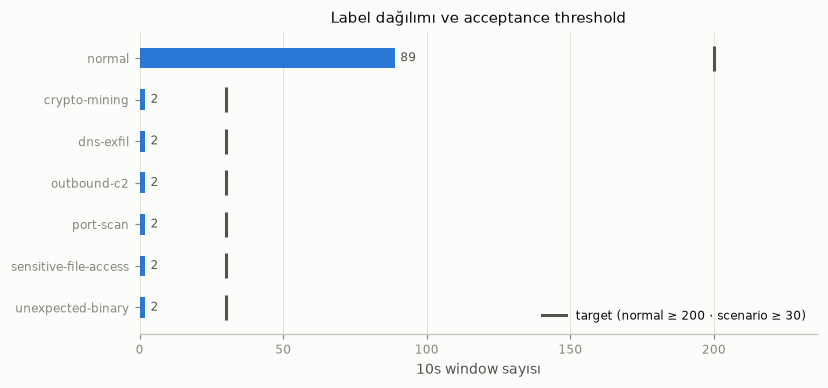

,label,windows,target,status
0,normal,89,200,❌ fail
1,crypto-mining,2,30,❌ fail
2,dns-exfil,2,30,❌ fail
3,outbound-c2,2,30,❌ fail
4,port-scan,2,30,❌ fail
5,sensitive-file-access,2,30,❌ fail
6,unexpected-binary,2,30,❌ fail


In [31]:
fig, overview = charts.label_distribution(df, WINDOW)
plt.show()
overview.assign(status=[style.status_text(w >= t)
                        for w, t in zip(overview["window sayısı"], overview["hedef"])])

### 4.2 Runtime katmanı normal davranış hakkında hiçbir şey söylemiyor

Bu, hacim sorunundan daha ciddi. Demo iş yükü (Online Boutique) gerçek pod'lardan
neredeyse hiç runtime olayı üretmiyor. Konteynerler uzun ömürlü süreçler çalıştırıyor ve
yeni süreç doğurmuyor. Bu yüzden `normal` sınıfının runtime feature'ları sıfıra çok
yakın.

Ölçüt: `normal` satırların en az bir runtime feature'ı sıfırdan farklı olma oranı
(`vd.normal_runtime_coverage`).

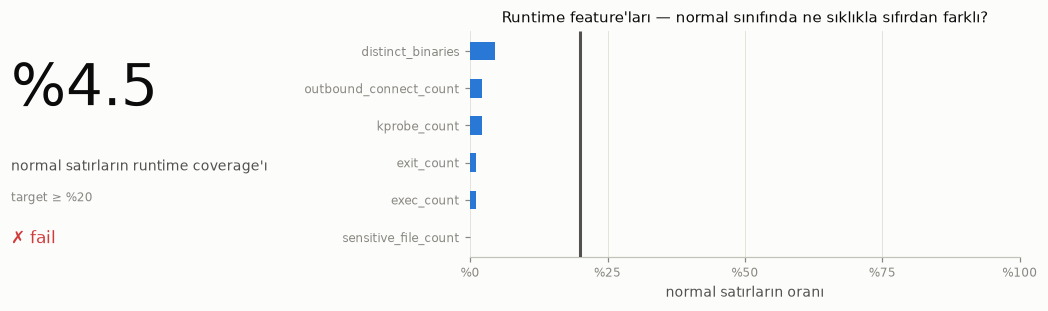

In [32]:
fig, coverage = charts.coverage_panel(df)
plt.show()

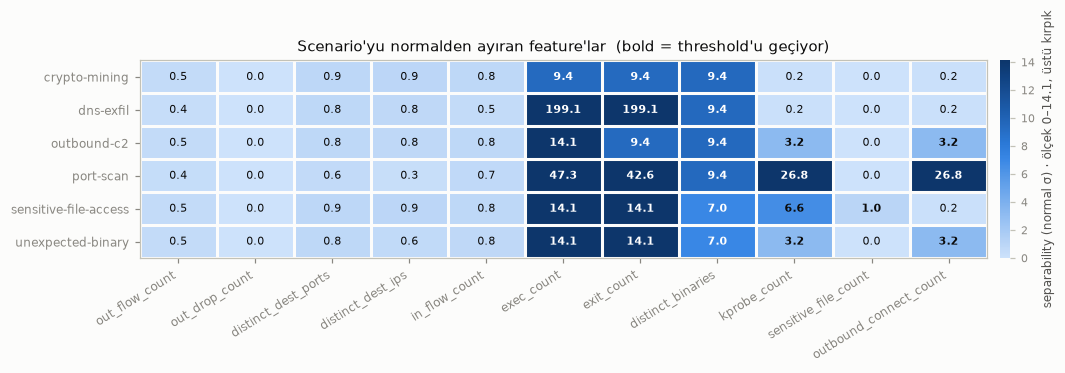

In [33]:
fig, scores, scenarios = charts.separability_heatmap(df)
plt.show()

### 4.3 Peki bu skorlar nereden geliyor?

Heatmap'teki skorlar onlarca, hatta yüzlerce σ çıkıyor ve ilk bakışta etkileyici
görünüyor. Ama skorun tanımına bakalım:

> skor = |saldırı ortalaması − normal ortalaması| / normalin standart sapması

Paydada normal sınıfının kendi değişkenliği var. Normalde runtime aktivitesi neredeyse
hiç olmadığı için bu payda sıfıra yaklaşıyor ve küçük farklar devasa skorlara
dönüşüyor. Yani yüksek skor "güçlü bir sinyal var" demek değil; "normalin öğrenilecek
bir değişkenliği yok" anlamına da gelebilir. Önce paydaya bakalım.

In [34]:
normal = df[df.label == "normal"]
attack = df[df.label != "normal"]


def _num(frame, col):
    return pd.to_numeric(frame[col], errors="coerce").fillna(0)


runtime_stats = pd.DataFrame([
    {
        "runtime feature": c,
        "normal ort.": round(float(_num(normal, c).mean()), 3),
        "normal std": round(float(_num(normal, c).std(ddof=0)), 3),
        "spread (vd)": round(vd.normal_spread(_num(normal, c)), 3),
        "normal nonzero": f"{int((_num(normal, c) > 0).sum())}/{len(normal)}",
        "saldırı ort.": round(float(_num(attack, c).mean()), 2),
    }
    for c in RT_COLS
])
print("`spread (vd)` = validate_dataset.py'nin skorda payda olarak kullandığı değer")
print("(std=0 ise 1.0'a düşer; skoru sonsuza gitmekten korur)")
runtime_stats.sort_values("normal std")

`spread (vd)` = validate_dataset.py'nin skorda payda olarak kullandığı değer
(std=0 ise 1.0'a düşer; skoru sonsuza gitmekten korur)


,runtime feature,normal mean,normal std,spread (vd),normal nonzero,attack mean
4,sensitive_file_count,0.000,0.000,1.000,0/89,0.17
0,exec_count,0.011,0.105,0.105,1/89,5.25
1,exit_count,0.011,0.105,0.105,1/89,5.08
3,kprobe_count,0.022,0.148,0.148,2/89,1.00
5,outbound_connect_count,0.022,0.148,0.148,2/89,0.83
2,distinct_binaries,0.045,0.207,0.207,4/89,1.83


In [35]:
# Skor ile paydayı YAN YANA: her scenario'nun en iyi feature'ı, skoru ve
# o feature'ın normaldeki standart sapması.
rows = []
for s in scenarios:
    best = vd.best_discriminator(df, s)
    if not best:
        rows.append({"scenario": s, "best feature": "—", "skor (normal σ)": None,
                     "normal std": None, "normal max": None, "saldırı ort.": None})
        continue
    n = _num(normal, best["feature"])
    rows.append({
        "scenario": s,
        "best feature": best["feature"],
        "skor (normal σ)": round(best["score"], 1),
        "normal std": round(float(n.std(ddof=0)), 3),
        "normal max": float(n.max()),
        "saldırı ort.": round(best["attack_mean"], 1),
    })
score_artifact = pd.DataFrame(rows).sort_values("skor (normal σ)", ascending=False)
score_artifact

,scenario,best feature,score (normal σ),normal std,normal max,attack mean
1,dns-exfil,exec_count,199.1,0.105,1.0,21.0
3,port-scan,exec_count,47.3,0.105,1.0,5.0
4,sensitive-file-access,exec_count,14.1,0.105,1.0,1.5
2,outbound-c2,exec_count,14.1,0.105,1.0,1.5
5,unexpected-binary,exec_count,14.1,0.105,1.0,1.5
0,crypto-mining,distinct_binaries,9.4,0.207,1.0,2.0


#### Tek kurallı bir deney: hiç model eğitmeden

Paydanın sorun olduğunu görmenin en kolay yolu hiç model eğitmemek. Tek kurallı bir
sınıflandırıcı kuralım:

> "Bu window'da feature sıfırdan farklıysa → saldırı."

Bir kuralın işe yaraması için iki şey gerekir: saldırı pencerelerinde tetiklenmeli,
normal pencerelerde tetiklenmemeli. Aşağıdaki tablo ikisini de ölçüyor. Referans
noktası çoğunluk sınıfı: hiçbir şey öğrenmeden "hep normal" demenin doğruluğu.

In [ ]:
actual = df.label != "normal"
baseline = float((~actual).mean())      # hiçbir şey öğrenmeden "hep normal" demek

rows = []
for c in ALL_COLS:
    fires = _num(df, c) > 0
    rows.append({
        "feature": c,
        "katman": "çalışma zamanı" if c in RT_COLS else "ağ",
        "kural doğruluğu": round(float((fires == actual).mean()), 3),
        "normalde tetiklenme": round(float(fires[~actual].mean()), 3),
        "saldırıda tetiklenme": round(float(fires[actual].mean()), 3),
    })
rules = pd.DataFrame(rows)
rules["çoğunluk sınıfına fark"] = (rules["kural doğruluğu"] - baseline).round(3)
rules = rules.sort_values("kural doğruluğu", ascending=False)
print(f"çoğunluk sınıfı baseline (hep 'normal' demek): {baseline:.3f}")
rules

In [ ]:
# Aynı tablonun görseli: her feature için iki bar.
order = rules["feature"].tolist()
by_feature = rules.set_index("feature")
y = list(range(len(order)))[::-1]
fig, ax = plt.subplots(figsize=(8.4, 5.0))
ax.barh([yi + 0.2 for yi in y], [by_feature.loc[f, "normalde tetiklenme"] for f in order],
        height=0.36, color=style.S1, zorder=3, label="normal'de tetiklenme")
ax.barh([yi - 0.2 for yi in y], [by_feature.loc[f, "saldırıda tetiklenme"] for f in order],
        height=0.36, color=style.S2, zorder=3, label="saldırıda tetiklenme")
ax.set_yticks(y)
ax.set_yticklabels(order)
ax.set_xlim(0, 1)
ax.set_xticks([0, .25, .5, .75, 1])
ax.set_xticklabels(["%0", "%25", "%50", "%75", "%100"])
ax.set_xlabel("kuralın tetiklenme oranı")
ax.xaxis.grid(True)
style.strip_frame(ax)
# Legend eksen DIŞINDA: satırların çoğu tam genişliğe uzandığı için içeride
# her konum bir bar'ın üstüne biner.
ax.legend(loc="lower left", bbox_to_anchor=(0, 1.01), ncol=2)
# Başlık legend'ın ÜSTÜNDE kalsın (pad olmadan legend başlığa biner).
ax.set_title('Tek kurallı sınıflandırıcı: "feature > 0 ⇒ saldırı"', pad=30)
plt.tight_layout()
plt.show()

In [ ]:
dead = rules[rules["saldırıda tetiklenme"] == 0]
clean = rules[(rules["normalde tetiklenme"] == 0) & (rules["saldırıda tetiklenme"] > 0)]
beats = rules[rules["çoğunluk sınıfına fark"] > 0.02]

dead_names = ", ".join(dead["feature"]) if len(dead) else "—"
print(f"hiç tetiklenmeyen (ölü) feature                : {len(dead)}/{len(rules)}  → {dead_names}")
print(f"normalde hiç tetiklenmeyip saldırıda tetiklenen : {len(clean)}/{len(rules)}")
print(f"baseline'ı >2 puan geçen kural                 : {len(beats)}/{len(rules)}")
if len(clean):
    print()
    print(clean[["feature", "katman", "kural doğruluğu", "saldırıda tetiklenme"]].to_string(index=False))
    print("\n→ Tek kuralla baseline'ı geçen feature'lar yukarıda. Bunların skoru yüksek")
    print("  çıkıyorsa sebebi paydanın (normal std) küçüklüğüdür; 'temiz sinyal' değil.")
else:
    print("\n→ Normalde hiç tetiklenmeyip saldırıda tetiklenen feature YOK: tek kurallı")
    print("  ayrım mümkün değil, her kural normalde de yanlış pozitif üretiyor.")

#### Nasıl okumalı

Üç şeye birlikte bakmak gerekiyor; hiçbiri tek başına tespit gücü anlamına gelmiyor.

1. **Payda (`normal std`).** Sıfıra yakın bir std skoru şişirir. Bu "mükemmel tespit"
   değil, "normal hakkında bilgi yok" demektir. `spread (vd)` kolonu, std=0 olduğunda
   paydanın 1.0'a düştüğünü gösteriyor; yani skor ham farka indirgeniyor.
2. **Kuralın normalde tetiklenmesi.** Normali tetikleyen bir kural yanlış pozitif
   üretir; `fires on normal` kolonu bunu gösteriyor.
3. **Kuralın saldırıda tetiklenmesi.** Hiç tetiklenmeyen bir feature ölüdür. Örneğin bu
   ortamda hiç düşmeyen bir verdict, doğruluğu yalnızca çoğunluk sınıfı kadar olan bir
   kural üretir; yani hiçbir şeyi ayırmaz.

### 4.4 Bu, tezin iddiası için ne anlama geliyor?

Tezin özgün katkısı iki katmanı feature seviyesinde birleştirmek. Füzyonun katma değeri,
ikinci katmanın bağımsız bilgi taşımasına bağlı.

Runtime feature'ları normal hakkında öğrenilecek bir değişkenlik taşımıyorsa, model ağ
ve runtime feature'larını birleştirmeyi değil, "runtime'da olay var mı" sorusunu
cevaplamayı öğrenir. Bu durumda füzyonun katma değeri ölçülemez; çünkü ölçülecek ikinci
bir bilgi yok.

Bu yüzden FAZ 3.5 "toplamayı tekrarla" işi değil. Tezin iddiasını savunulabilir kılmak
için zorunlu bir faz.

## 5 · Plan: neyi, neden değiştiriyoruz

Bu iş için ayrı bir faz açtık. Sorun toplamayı tekrarlamak değil; veriyi üretme
biçimini düzeltmek. Dört karar var.

**1. Baseline'a sürekli gerçek runtime aktivitesi eklemek.** Bu, §4.2'deki sorunun
doğrudan çözümü. Kesintisiz bir bakım iş yükü seçtik. CronJob'ı eledik; dakikada bir
çalışan bir iş, 10 saniyelik window'da kabul kriterinin sınırında kalıyordu. İş yükü
`runAsNonRoot` çalışıyor, böylece hassas dosyalara erişemiyor ve `normal` sınıfına
`security_file_open` sızmıyor. Saldırı pod'uyla aynı imajı kullanıyor; böylece model
"busybox ⇒ saldırı" gibi bir kısayol öğrenemiyor.
*Dürüstlük notu: bu iş yükü yapay. Tezde açıkça "yapay olarak eklenmiş gerçek iş yükü"
olarak yazmak gerekiyor. Gerçek kümelerde bu tür aktivite cron, yedekleme ve log
rotasyonundan doğar.*

**2. CrashLoop'ları düzeltmek.** Burada bir yan bulgu çıktı: sorun uygulamada değil,
probe bütçesindeydi. Pod'un portu kubelet'ten yaklaşık 20–35 saniye sonra erişilebilir
hâle geliyordu, ama liveness bütçesi 15 saniyeydi (initialDelay yok, period 5 sn,
failureThreshold 3). Yani probe, ilk başarılı denemeden önce container'ı SIGKILL
ediyordu ve döngü hiç bitmiyordu. 120 saniyelik `startupProbe` ile çözdük ve doğruladık.
*Sıralama önemliydi: crashloop'u düzeltmek, normal sınıfındaki tek runtime aktivitesi
kaynağını da ortadan kaldırdı. Bu yüzden 1. kararı önce uyguladık.*

**3. Etiketlemeyi zaman ve kimlik tabanlı yapmak.** Eski etiketleme yalnızca pod adı
önekine bakıyordu; bu yüzden gerçek bir pod üzerinden koşan saldırı sessizce `normal`
kalıyordu. Yeni kural iki koşulu birlikte arıyor: window'un yarısından fazlası saldırı
aralığında olmalı ve pod o saldırının hedefi olmalı. Zaman tek başına yetmez, çünkü
saldırı aralığındaki bütün pod'lar etiket alırdı. Kimlik tek başına da yetmez, çünkü
eski davranışa döneriz.

**4. Saldırıları döngüye almak ve gerçek pod'ların içinden çalıştırmak.** Eski tasarım
her senaryo için geçici bir busybox veya curl pod'u açıyordu. Bunun üç sorunu vardı:
hacim üretmiyordu (§4.1); normal pencereler Online Boutique imajlarından, saldırı
pencereleri busybox'tan geldiği için model imajı öğrenebilirdi; hedef pod bilgisi
kaydedilmiyordu. Artık saldırılar çalışan gerçek bir servis pod'unda `kubectl exec` ile
koşuyor.

**Window boyutu kararı.** Senaryolar 6 dakika sürdüğünde kabul kriteri (senaryo başına
en az 30 window) 10 saniyelik window'da karşılanıyor; 30 saniyede eşiğin altında
kalıyor. Bu şimdilik bir ön karar. Kesinleşmesi
`data-quality-dashboard.ipynb` §7'deki 5/10/30 saniye ölçümüne bağlı.

### Bir yan bulgu: kısa saldırı + kaba window = senaryo kayboluyor

Eski veri setini yeni etiketleme kuralıyla yeniden etiketlediğimizde
`sensitive-file-access` senaryosu tamamen kayboldu. Saldırı 23 saniye sürüyor ve hiçbir
window'un yarısından fazlasını kapsamıyor. Eski veride bu senaryo "temiz sinyal" diye
anılıyordu; aslında etiketleme kusuru sayesinde görünüyordu. Bu da 4. kararın yalnızca
hacim için değil, etiketlemenin çalışması için de gerekli olduğunu gösteriyor.

## 6 · Mevcut durum: kabul kriterleri

§2'deki faz indeksi "hangi fazdayız" sorusunu cevaplıyor. Bu tablo ise verinin
kendisinin eşiği geçip geçmediğini ölçüyor. İkisi farklı şeyler: bir faz uygulanıyor
olabilir ama veri henüz kabul edilebilir olmayabilir.

Aşağıdaki tablo `make validate` komutunun bastığı tablonun aynısı; aynı fonksiyon, aynı
eşikler. Kriter tutmazsa `make validate` sıfırdan farklı bir kodla çıkıyor ve FAZ 4
bloke kalıyor. Yani "veri topladık" demek "devam edebiliriz" demek değil.

In [ ]:
undetectable = [s for s in scenarios if vd.best_discriminator(df, s) is None]

raw = pd.DataFrame(vd.check_targets(summary, coverage, undetectable),
                   columns=["criterion", "actual", "target", "passed"])
all_pass = bool(raw["passed"].all())
raw.assign(status=[style.status_text(p) for p in raw["passed"]]) \
   .drop(columns=["passed"])

In [ ]:
print("SONUÇ: " + ("kabul edilebilir — FAZ 4 açılabilir" if all_pass
                   else "FAZ 4'e hazır değil — kriterler yukarıda"))
print(f"\nnot: bu tablo {'GÜNCEL' if not stale else 'ESKİMİŞ'} veriyle üretildi "
      f"({len(df)} satır, {features_mtime:%Y-%m-%d})")

## 7 · Sıradaki adım ve riskler

**Sıradaki adım.** Uzun ve temiz bir toplama koşusu (uzun bir baseline ve 6 kez
tekrarlanan saldırılar) → `make features` → bu sunumu ve dashboard'u yeniden
çalıştırmak → window kararını (5/10/30 saniye) ölçüme dayanarak vermek.

Kabul kriterleri tutarsa FAZ 4 açılıyor. Tutmazsa hangi kriterin tutmadığı §6'daki
tabloda görünüyor ve o kriteri hedefliyoruz.

| Risk | Ne yapıyoruz |
|---|---|
| Eklediğimiz bakım iş yükü yapay | Tezde açıkça belirtilecek |
| L7 kapsam dışı; `dns-exfil` gerçek DNS sinyaliyle değil `exec_count` ile ayrışıyor | Bunu bir tespit boşluğu olarak yazacağız ve FAZ 5'te `CiliumNetworkPolicy` ile kapatacağız |
| Bazı senaryolar sinyalsiz (`crypto-mining`, `outbound-c2`) | Kabul kriteri, her senaryonun en az bir feature'da ayırt edilebilir olması. Gösterilemeyeni ya güçlendireceğiz ya tezden çıkaracağız |
| Tetragon, selektörlü policy'leri `kubectl exec` süreçlerini o sürece bağlayamıyor | Ölçülmüş bir ortam kısıtı. `sensitive-file-access` bu yüzden ayrı bir pod'da koşuyor. Yöntem ve sınırlılıklar bölümüne girecek |
| Probe veya kaynak ayarları veri üretimini sessizce bozabilir | Her koşudan sonra tazelik hücresini ve §6 tablosunu kontrol ediyoruz |

**Bu faz neden atlanamaz?** Atlarsak FAZ 4'te eğitilen her model bu veri setinde çok
yüksek doğruluk verir ve bu tamamen anlamsız olur. Çünkü model anomaliliği değil, "bu
pencerede bir süreç doğdu mu" sorusunu cevaplıyordur.

---

## Kaynaklar

| Ne | Nerede |
|---|---|
| Kanonik durum ve sayılar | `roadmap/00-durum.md` |
| Faz indeksi (§2 buradan canlı okuyor) | `roadmap/README.md` |
| Tez tanımı: problem, katkı, mimari | `roadmap/01-tez-tanimi.md` |
| Bu fazın planı ve kararları | `roadmap/06-faz3.5-veri-kalitesi.md` |
| Riskler ve karar günlüğü | `roadmap/99-riskler-ve-kararlar.md` |
| Ölçüm mantığı (tek tek kaynak) | `src/validate_dataset.py` |
| Feature şeması | `src/features/extract_features.py` |
| Tam teknik doğrulama | `notebooks/data-quality-dashboard.ipynb` |
| Ham veriyi inceleme | `notebooks/parquet-explorer.ipynb` |